# Base Modeling

Este notebook parte del **dataset final** de Data Preparation (`dataset_final.parquet`, guardado en la última celda de `DataPreparation.ipynb`).

Aquí se hacen la normalización de los datos y la definición de los folds de validación con `TimeSeriesSplit`.

### 1. Conectar con Google Drive e importar librerías

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


In [2]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [3]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [4]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [5]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

In [6]:
TARGET = "pct_posible_cola"
N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

# Normalización de datos

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd

TARGET = "pct_posible_cola"
WINDOW = 48
HORIZON = 48

df = load_dataset().sort_values("bloque_tiempo").reset_index(drop=True)
df = pd.get_dummies(df, columns=["ms", "temporada"], dtype="float32")

df["cola"] = (df[TARGET] > 0.5).astype("float32")
y_all = df["cola"].values

X = df.drop(columns=["bloque_tiempo"])

dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
categoricas = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numericas = [c for c in X.select_dtypes(include="number").columns
             if c not in dummies and c != "cola"]
binarias = dummies + ["cola"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Que devuelva un DataFrame directamente (sklearn >= 1.2)
preprocessor.set_output(transform="pandas")

X_normalizado = preprocessor.fit_transform(X)

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


# Separación de train y tests

La arquitectura y el umbral se seleccionan con validación. El test se reserva para comparar el rendimiento final de cada variante.


In [8]:
n = len(X)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X.iloc[:n_train])
X_all = preprocessor.transform(X).astype("float32").values

def make_windows(X, y, window, horizon):
    m = len(X) - window - horizon + 1
    idx = np.arange(window)[None, :] + np.arange(m)[:, None]
    return X[idx], y[np.arange(m) + window + horizon - 1]

Xw, yw = make_windows(X_all, y_all, WINDOW, HORIZON)
t_obj = np.arange(len(yw)) + WINDOW + HORIZON - 1   

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = Xw[train], yw[train]
X_val, y_val = Xw[val], yw[val]
X_test, y_test = Xw[test], yw[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

# Extramos el array de fechas directamente del df original antes de transformar
fechas = df["bloque_tiempo"].values

splits = {
    "Train": train,
    "Val":   val,
    "Test":  test
}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = fechas[indices_bloque[0]]
    fecha_fin = fechas[indices_bloque[-1]]
    num_ventanas = len(indices_bloque)
    
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {num_ventanas}")

X_train: (125799, 48, 29) | X_val: (26978, 48, 29) | X_test: (26978, 48, 29)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01T16:30:00.000000000 | Fin: 2024-12-22T07:00:00.000000000 | Ventanas: 125799
Val    | Inicio: 2024-12-22T07:00:00.000000000 | Fin: 2025-06-27T15:30:00.000000000 | Ventanas: 26978
Test   | Inicio: 2025-06-27T15:30:00.000000000 | Fin: 2025-12-31T23:30:00.000000000 | Ventanas: 26978


In [9]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lstm_model import LSTMModel
else:
  from model_base import BaseModel
  from lstm_model import LSTMModel

import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping
from pathlib import Path

model_base: BaseModel = LSTMModel()
model_path = Path.cwd()
model_output_dir = model_path / ".." / ".." / "models" / "lstm"
model_output_dir.mkdir(parents=True, exist_ok=True)
architectures = ("base", "dense", "norm", "norm+drop")
class_labels = np.unique(y_train.astype(int))
if not np.array_equal(class_labels, np.array([0, 1])):
    raise ValueError("El conjunto de entrenamiento debe contener ambas clases.")

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=y_train.astype(int),
)
class_weight = dict(zip(class_labels, class_weights))
training_results = {}


In [10]:
for architecture in architectures:
    tf.keras.utils.set_random_seed(42)
    model = model_base.compile(
        input_shape=X_train.shape[1:],
        v=architecture,
    )
    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
        )
    ]
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=128,
        class_weight=class_weight,
        callbacks=callbacks,
        shuffle=True,
        verbose=1,
    )
    validation_probabilities = model.predict(X_val, verbose=0).ravel()
    training_results[architecture] = {
        "model": model,
        "history": history,
        "validation_probabilities": validation_probabilities,
    }


Epoch 1/50
983/983 ━━━━━━━━━━━━━━━━━━━━ 135s 134ms/step - accuracy: 0.6390 - auc: 0.7130 - loss: 0.6205 - precision: 0.2475 - recall: 0.7165 - val_accuracy: 0.4254 - val_auc: 0.6011 - val_loss: 0.9158 - val_precision: 0.4254 - val_recall: 1.0000
Epoch 2/50
983/983 ━━━━━━━━━━━━━━━━━━━━ 110s 112ms/step - accuracy: 0.6494 - auc: 0.7195 - loss: 0.6158 - precision: 0.2527 - recall: 0.7104 - val_accuracy: 0.4254 - val_auc: 0.6130 - val_loss: 0.9062 - val_precision: 0.4254 - val_recall: 1.0000
Epoch 3/50
983/983 ━━━━━━━━━━━━━━━━━━━━ 114s 115ms/step - accuracy: 0.6529 - auc: 0.7224 - loss: 0.6136 - precision: 0.2547 - recall: 0.7099 - val_accuracy: 0.4329 - val_auc: 0.6112 - val_loss: 0.8988 - val_precision: 0.4286 - val_recall: 0.9992
Epoch 4/50
983/983 ━━━━━━━━━━━━━━━━━━━━ 116s 118ms/step - accuracy: 0.6556 - auc: 0.7264 - loss: 0.6105 - precision: 0.2567 - recall: 0.7109 - val_accuracy: 0.4360 - val_auc: 0.6125 - val_loss: 0.8957 - val_precision: 0.4299 - val_recall: 0.9991
Epoch 5/50
983/9

In [11]:
from sklearn.metrics import precision_recall_curve

validation_comparison = []
for architecture, result in training_results.items():
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        result["validation_probabilities"],
    )
    if thresholds.size == 0:
        raise ValueError(
            f"No se pudieron calcular umbrales para {architecture}."
        )
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )
    best_idx = int(np.argmax(f1_scores))
    result["threshold"] = float(thresholds[best_idx])
    result["validation_precision"] = float(precision[best_idx])
    result["validation_recall"] = float(recall[best_idx])
    result["validation_f1"] = float(f1_scores[best_idx])
    validation_comparison.append(
        {
            "Architecture": architecture,
            "Threshold": result["threshold"],
            "Validation Precision": result["validation_precision"],
            "Validation Recall": result["validation_recall"],
            "Validation F1": result["validation_f1"],
        }
    )

validation_comparison = pd.DataFrame(validation_comparison).sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)
display(validation_comparison)


,Architecture,Threshold,Validation Precision,Validation Recall,Validation F1
0,dense,0.628521,0.466876,0.918010,0.618964
1,base,0.647238,0.456282,0.944846,0.615385
2,norm,0.619924,0.447451,0.956696,0.609729
3,norm+drop,0.616140,0.442848,0.937092,0.601460



=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.591853
Precision 0.585644
   Recall 0.993493
 F1-Score 0.736900
  ROC-AUC 0.585896
   PR-AUC 0.627690


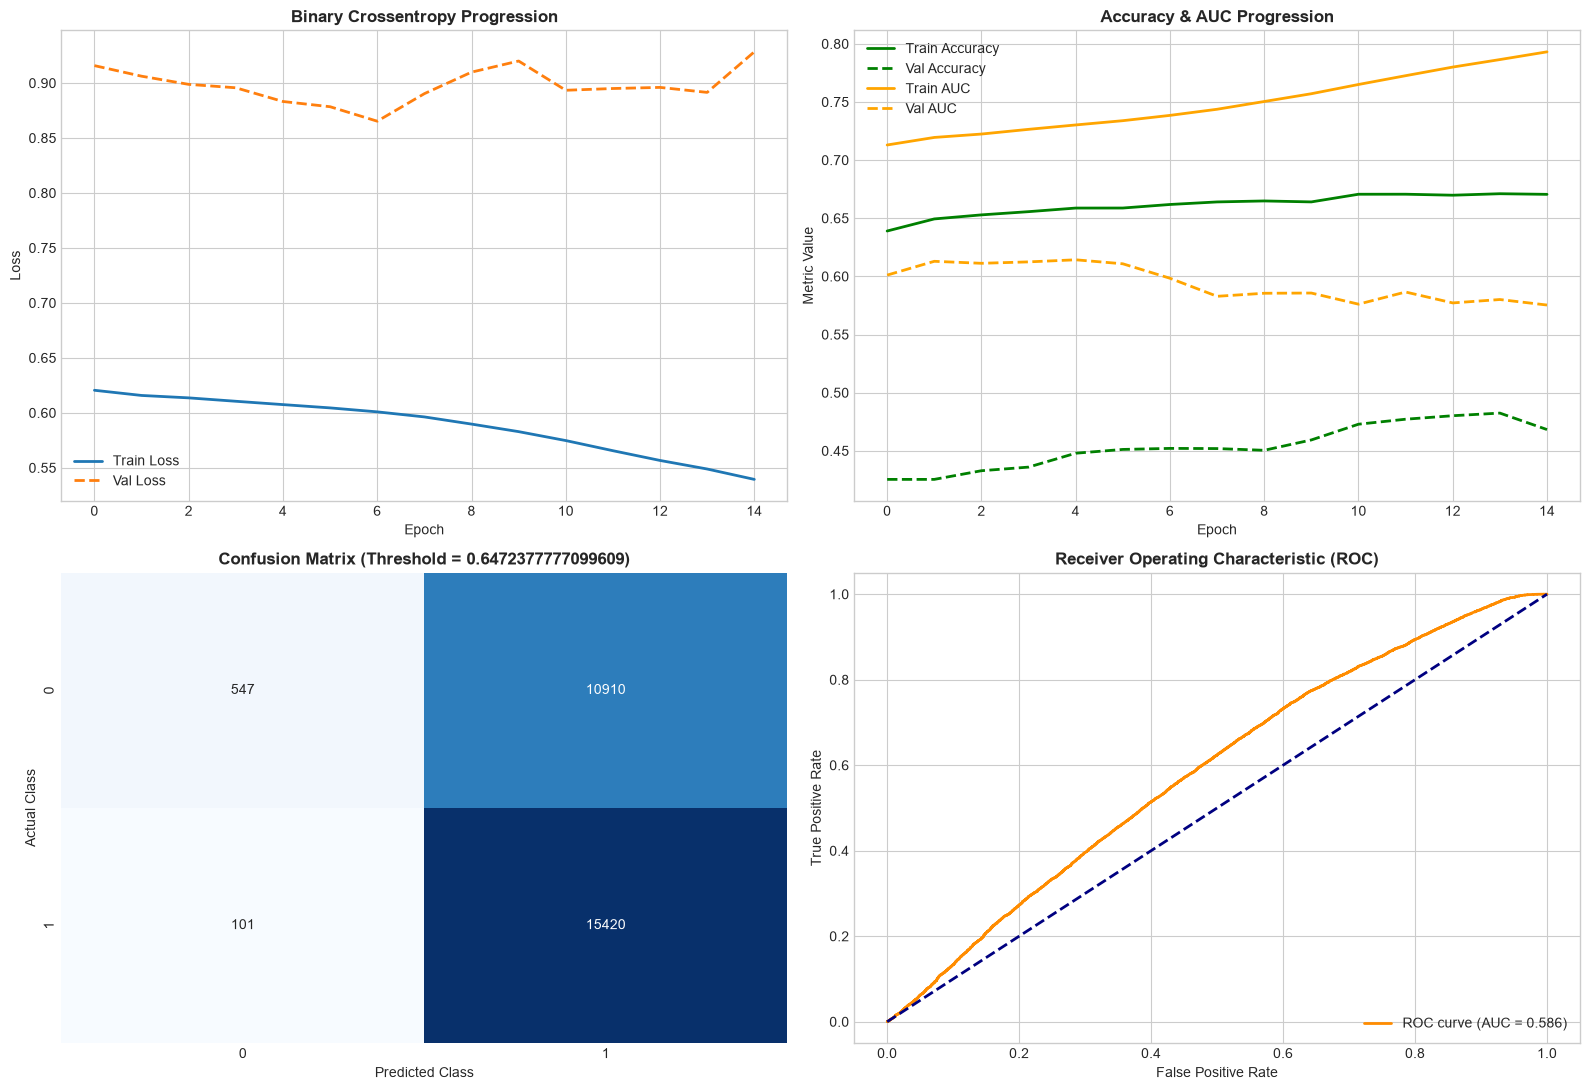


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.597413
Precision 0.590038
   Recall 0.983764
 F1-Score 0.737651
  ROC-AUC 0.587584
   PR-AUC 0.630194


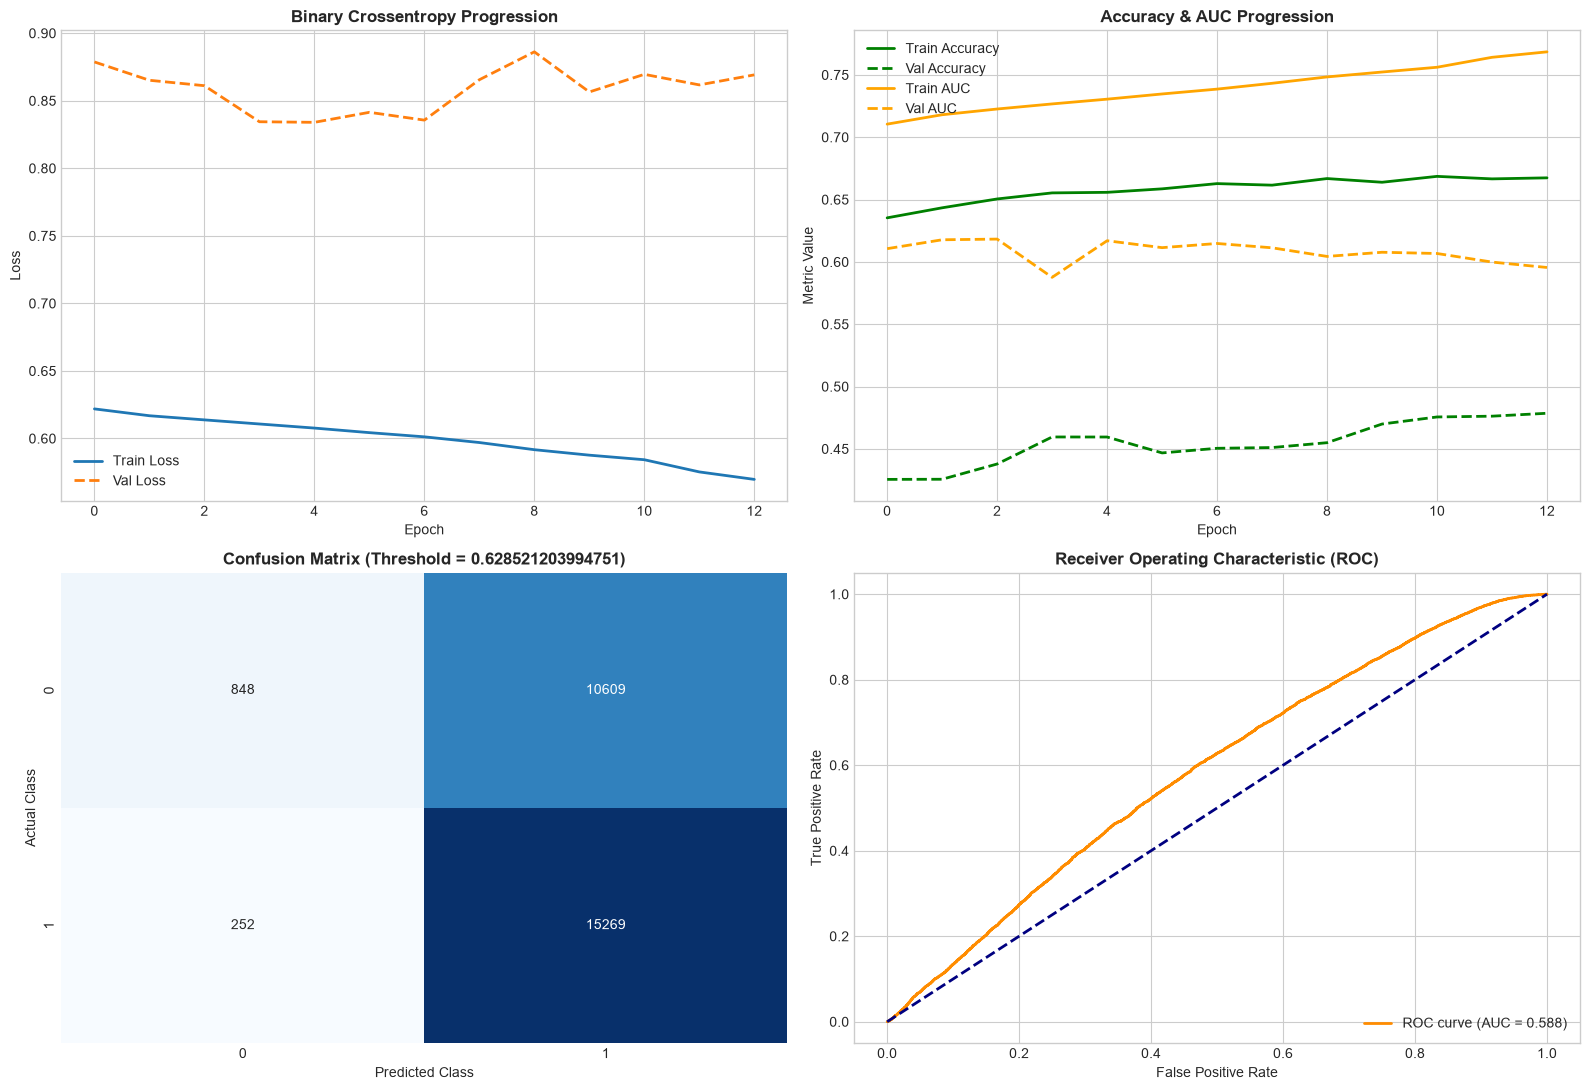


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.583438
Precision 0.581740
   Recall 0.981960
 F1-Score 0.730633
  ROC-AUC 0.606113
   PR-AUC 0.658261


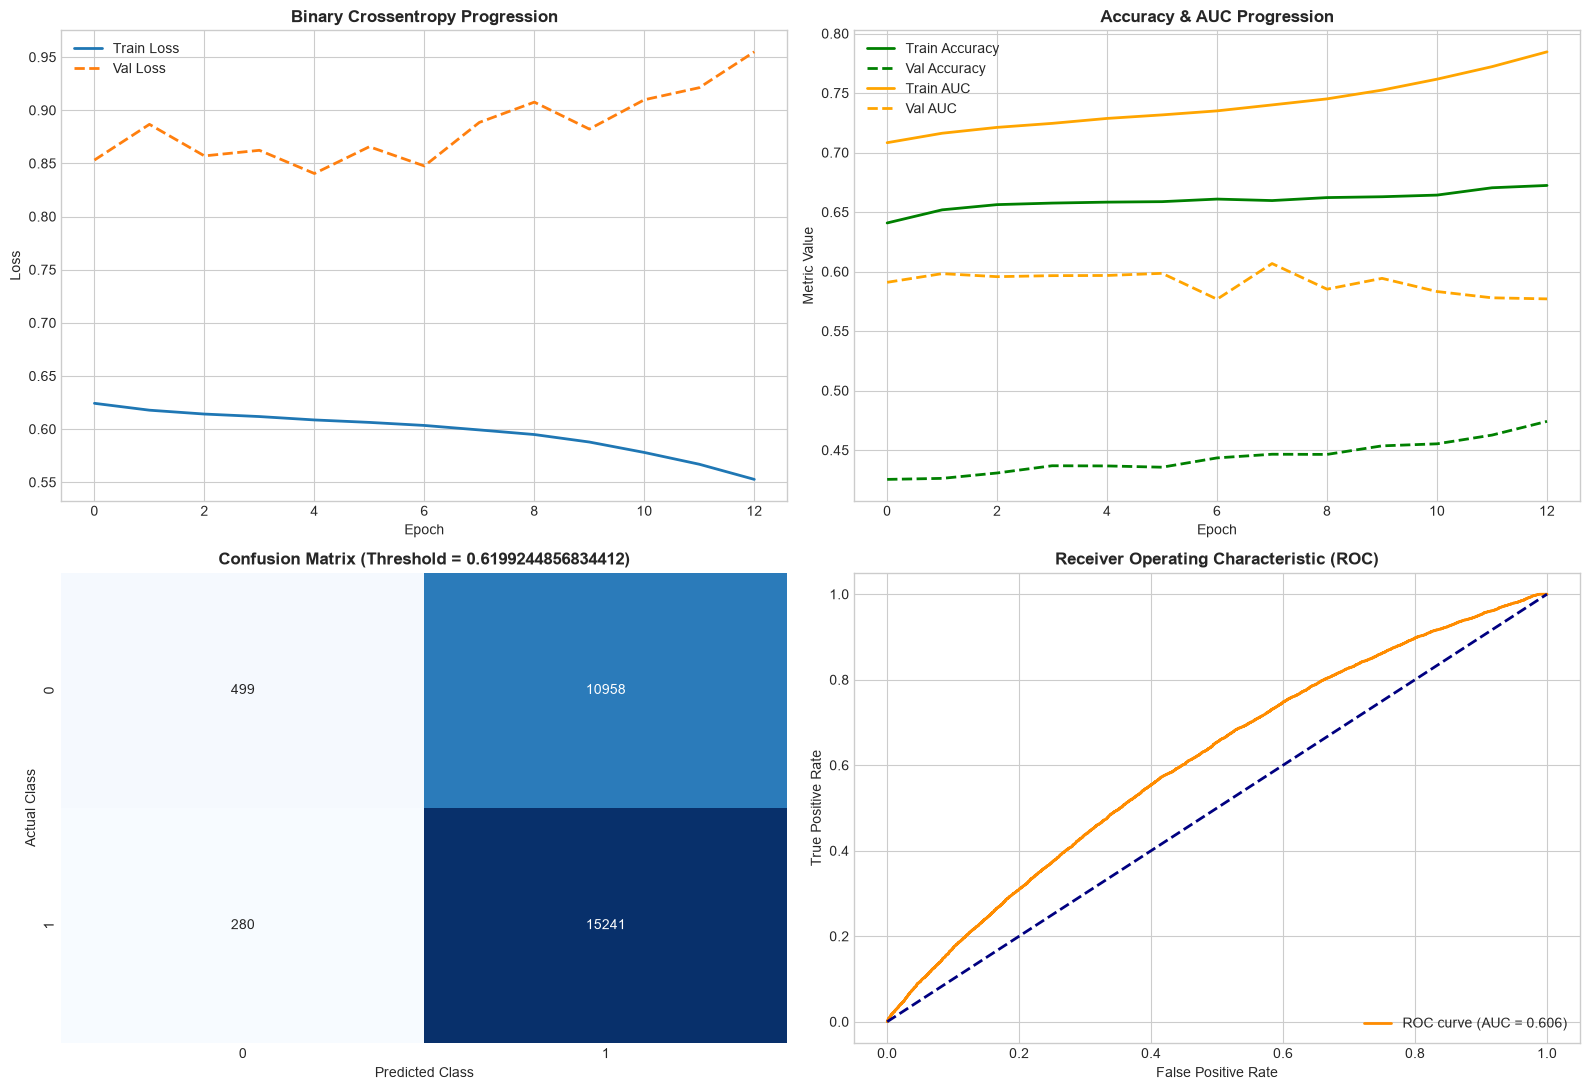


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.575988
Precision 0.576066
   Recall 0.995877
 F1-Score 0.729913
  ROC-AUC 0.600796
   PR-AUC 0.650344


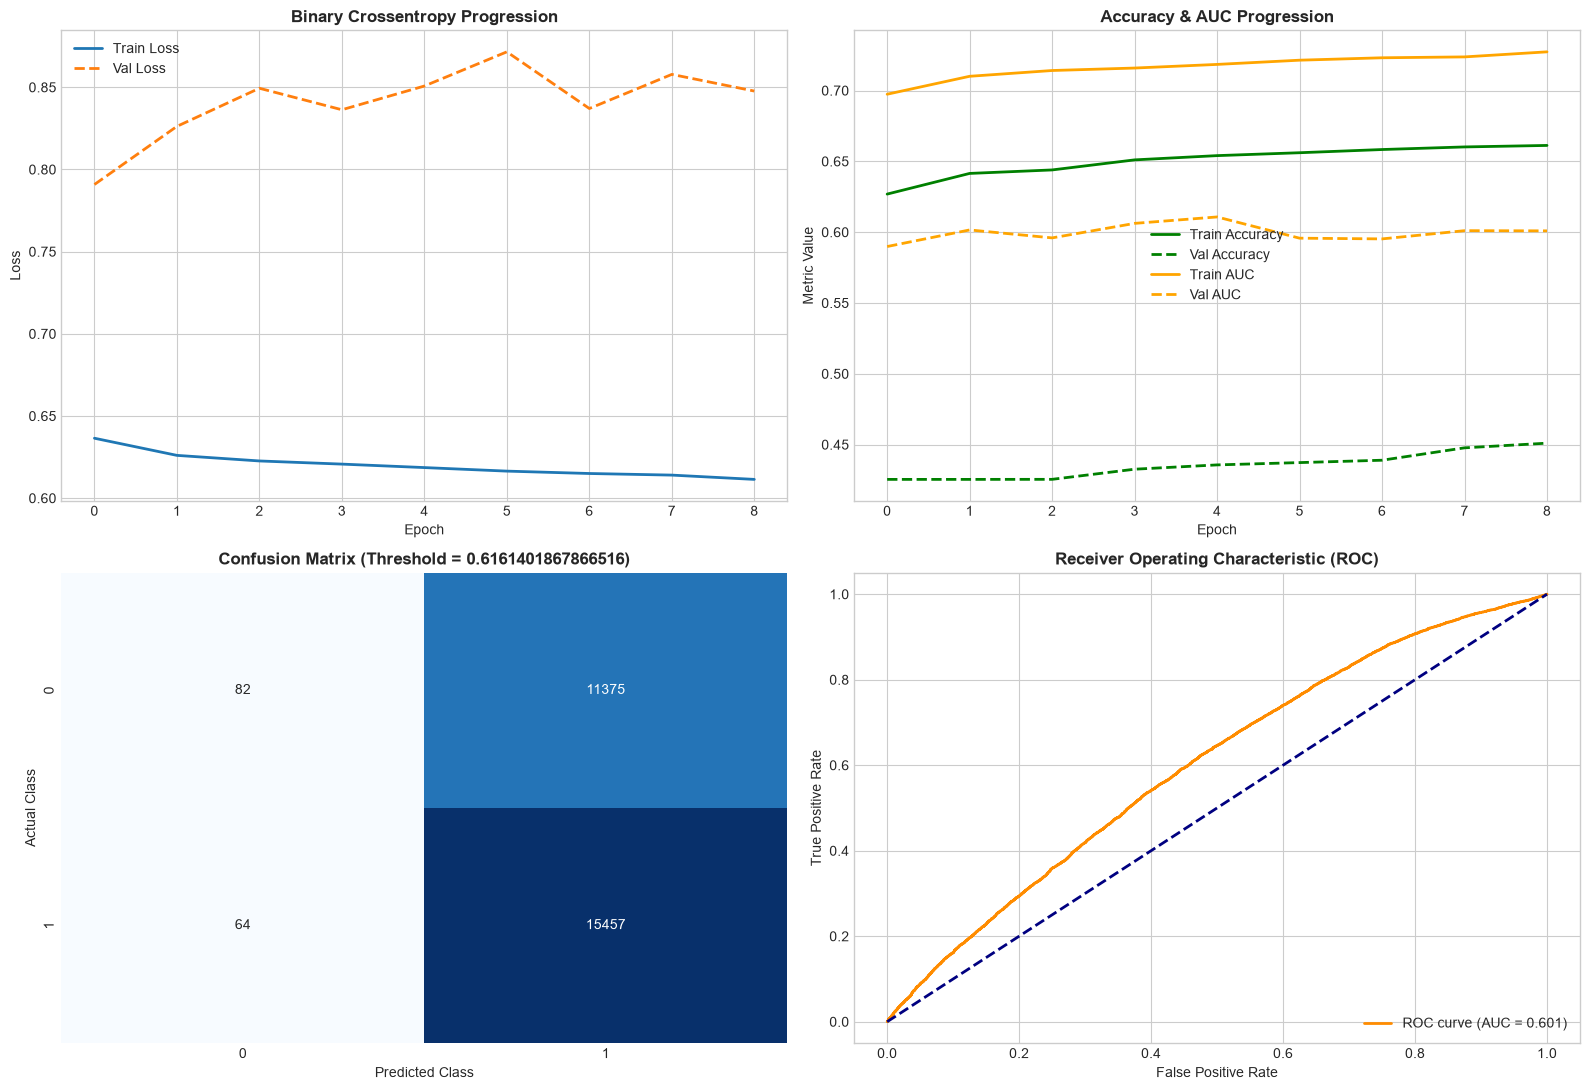

,Architecture,Threshold (validation),Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,dense,0.628521,0.618964,0.597413,0.590038,0.983764,0.737651,0.587584,0.630194
1,base,0.647238,0.615385,0.591853,0.585644,0.993493,0.736900,0.585896,0.627690
2,norm,0.619924,0.609729,0.583438,0.581740,0.981960,0.730633,0.606113,0.658261
3,norm+drop,0.616140,0.601460,0.575988,0.576066,0.995877,0.729913,0.600796,0.650344


Modelo seleccionado por F1 de validación: dense (umbral=0.6285, F1 validación=0.6190)


In [12]:
test_comparison = []
predictions_by_architecture = {}
metrics_by_architecture = {}

for architecture, result in training_results.items():
    predictions, metrics = model_base.evaluate(
        model=result["model"],
        history=result["history"],
        X_test=X_test,
        y_test=y_test,
        threshold=result["threshold"],
    )
    predictions_by_architecture[architecture] = predictions
    metrics_by_architecture[architecture] = metrics
    metric_values = dict(zip(metrics["Metric"], metrics["Value"]))
    test_comparison.append(
        {
            "Architecture": architecture,
            "Threshold (validation)": result["threshold"],
            "Validation F1": result["validation_f1"],
            "Test Accuracy": metric_values["Accuracy"],
            "Test Precision": metric_values["Precision"],
            "Test Recall": metric_values["Recall"],
            "Test F1": metric_values["F1-Score"],
            "Test ROC-AUC": metric_values["ROC-AUC"],
            "Test PR-AUC": metric_values["PR-AUC"],
        }
    )

comparison = pd.DataFrame(test_comparison).sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)
best_architecture = max(
    training_results,
    key=lambda name: training_results[name]["validation_f1"],
)
best_model = training_results[best_architecture]["model"]
best_threshold = training_results[best_architecture]["threshold"]
history = training_results[best_architecture]["history"]
model = best_model
df_preds = predictions_by_architecture[best_architecture]
df_metrics = metrics_by_architecture[best_architecture]
best_model_path = model_output_dir / "lstm_model.keras"
best_model_path.parent.mkdir(parents=True, exist_ok=True)
best_model.save(best_model_path)

display(comparison)
print(
    f"Modelo seleccionado por F1 de validación: {best_architecture} "
    f"(umbral={best_threshold:.4f}, "
    f"F1 validación={training_results[best_architecture]['validation_f1']:.4f})"
)


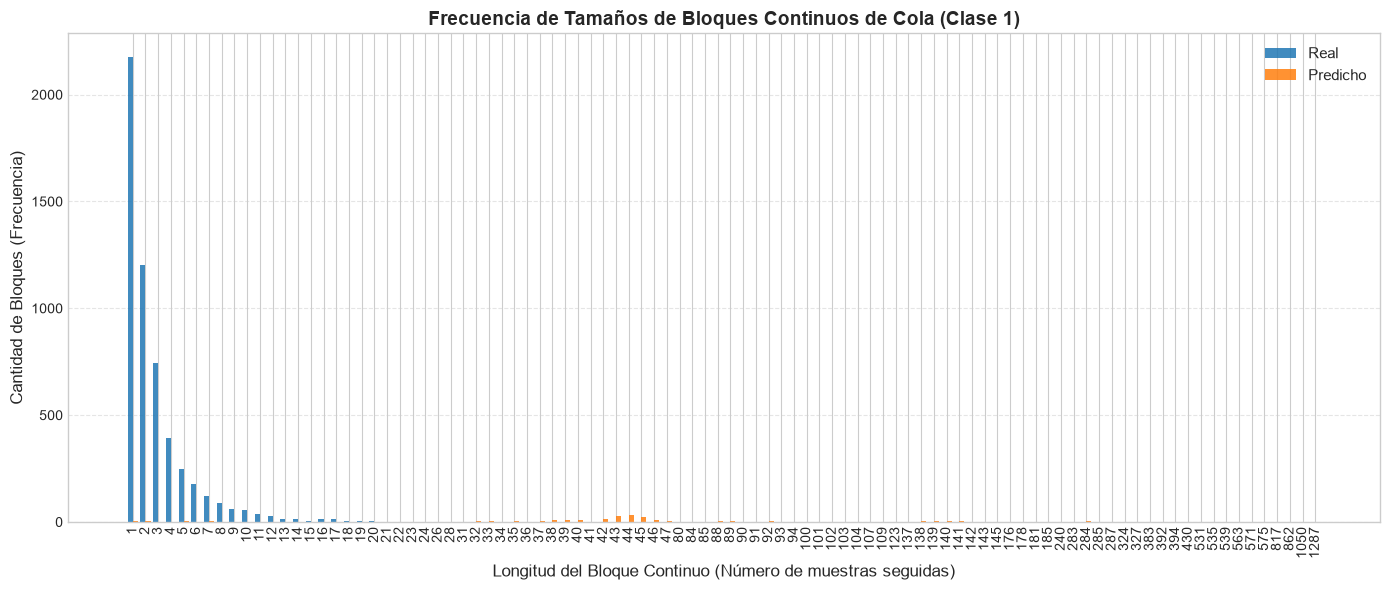

In [13]:
import matplotlib.pyplot as plt

def obtener_longitudes_bloques(series, clase=1):
    # Detecta cambios de estado para agrupar muestras consecutivas
    grupos = (series != series.shift()).cumsum()
    # Mide el tamaño de cada bloque si pertenece a la clase objetivo
    duraciones = series.groupby(grupos).apply(lambda g: len(g) if g.iloc[0] == clase else 0)
    return duraciones[duraciones > 0]

# 2. Obtener las duraciones para datos Reales y Predichos
bloques_reales = obtener_longitudes_bloques(df_preds['Actual'], clase=1)
bloques_predichos = obtener_longitudes_bloques(df_preds['Predicted Class'], clase=1)

# 3. Contar la frecuencia de cada tamaño de bloque (ej: cuántos bloques de 7, cuántos de 8, etc.)
freq_reales = bloques_reales.value_counts()
freq_predichos = bloques_predichos.value_counts()

# Combinar en un único DataFrame para graficar lado a lado
df_histograma = pd.DataFrame({
    'Real': freq_reales,
    'Predicho': freq_predichos
}).fillna(0).sort_index()

# 4. Mostrar resumen por consola (ej: "3 bloques de 8, 5 de 7")
# print("--- RESUMEN DE BLOQUES DE COLA (Real vs Predicho) ---")
# for longitud, row in df_histograma.iterrows():
#     if row['Real'] > 0 or row['Predicho'] > 0:
#         print(f"Longitud {int(longitud)} muestras: {int(row['Real'])} bloques Reales | {int(row['Predicho'])} bloques Predichos")

# 5. Graficar Histograma de Frecuencias
plt.figure(figsize=(14, 6))
ancho_barra = 0.4
x = np.arange(len(df_histograma))

plt.bar(x - ancho_barra/2, df_histograma['Real'], width=ancho_barra, label='Real', color='#1f77b4', alpha=0.85)
plt.bar(x + ancho_barra/2, df_histograma['Predicho'], width=ancho_barra, label='Predicho', color='#ff7f0e', alpha=0.85)

plt.title('Frecuencia de Tamaños de Bloques Continuos de Cola (Clase 1)', fontsize=14, fontweight='bold')
plt.xlabel('Longitud del Bloque Continuo (Número de muestras seguidas)', fontsize=12)
plt.ylabel('Cantidad de Bloques (Frecuencia)', fontsize=12)

# Ajustar etiquetas del eje X con las longitudes reales
plt.xticks(x, labels=[str(int(i)) for i in df_histograma.index], rotation=90 if len(df_histograma) > 20 else 0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()

plt.show()